In [ ]:
from bs4 import BeautifulSoup
import requests

/Users/hanoknaidu/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [ ]:
url='https://coinmarketcap.com/coins/'
page=requests.get(url)

In [ ]:
soup=BeautifulSoup(page.text,'html')

<!DOCTYPE html>
<html dir="ltr" lang="en"><head><meta charset="utf-8"/><meta content="ie=edge" http-equiv="x-ua-compatible"/><meta content="width=device-width, initial-scale=1, maximum-scale=1, user-scalable=no, shrink-to-fit=no" name="viewport"/><meta content="https://coinmarketcap.com/coins/" property="og:url"/><link href="https://coinmarketcap.com/coins/" rel="canonical"/><link href="https://coinmarketcap.com/ar/coins/" hreflang="ar" rel="alternate"/><link href="https://coinmarketcap.com/bg/coins/" hreflang="bg" rel="alternate"/><link href="https://coinmarketcap.com/cs/coins/" hreflang="cs" rel="alternate"/><link href="https://coinmarketcap.com/da/coins/" hreflang="da" rel="alternate"/><link href="https://coinmarketcap.com/de/coins/" hreflang="de" rel="alternate"/><link href="https://coinmarketcap.com/el/coins/" hreflang="el" rel="alternate"/><link href="https://coinmarketcap.com/coins/" hreflang="en" rel="alternate"/><link href="https://coinmarketcap.com/es/coins/" hreflang="es" re
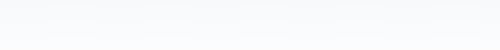
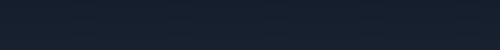

In [ ]:
print(soup)

In [ ]:
<span data-role="coin-name" title="Bitcoin" class="sc-c1554bc0-0 hhUhBo">Bitcoin<span class="sc-c1554bc0-0 iSUEMj coin-name-mobile"> price</span></span>

SyntaxError: invalid syntax (94132132.py, line 1)

In [ ]:
soup.find('span',class_='sc-c1554bc0-0')

<span class="sc-c1554bc0-0 biqTUv TopicItem_topic-title__KtZPk">Tokens with big upside in this rally? 🔎</span>

In [ ]:
spans = soup.find_all('span', class_='sc-c1554bc0-0')

for span in spans:
    text = span.text.strip()
    if text.startswith('$') and any(char.isdigit() for char in text):
        crypto_price = text
        break

print(crypto_price)

$78,185.10


In [ ]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36',
}

url = "https://coinmarketcap.com/currencies/bitcoin/"
response = requests.get(url, headers=headers)
soup = BeautifulSoup(response.text, 'html.parser')

# Get coin name from the page title (most reliable — doesn't depend on shifting classes)
coin_name = soup.find('title').text.split(' price today')[0].strip()

# Get price using the same filtering approach as before
spans = soup.find_all('span', class_='sc-c1554bc0-0')
crypto_price = None
for span in spans:
    text = span.text.strip()
    if text.startswith('$') and any(char.isdigit() for char in text):
        crypto_price = text
        break

print(coin_name)
print(crypto_price)

Bitcoin
$78,486.44


In [ ]:
df = pd.DataFrame([{'Coin Name': coin_name, 'Price': crypto_price}])
print(df)

  Coin Name       Price
0   Bitcoin  $78,486.44


In [ ]:
final_price=crypto_price.replace('$','')

In [ ]:
final_price

'78,486.44'

In [ ]:
from datetime import datetime
date_time=datetime.now()
print(date_time)

2026-08-21 18:47:33.008225


In [ ]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
from datetime import datetime

headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36',
}

url = "https://coinmarketcap.com/currencies/bitcoin/"
response = requests.get(url, headers=headers)
soup = BeautifulSoup(response.text, 'html.parser')

# Get coin name from the page title
coin_name = soup.find('title').text.split(' price today')[0].strip()

# Get price
spans = soup.find_all('span', class_='sc-c1554bc0-0')
crypto_price = None
for span in spans:
    text = span.text.strip()
    if text.startswith('$') and any(char.isdigit() for char in text):
        crypto_price = text
        break

# Get current timestamp
timestamp = datetime.now().strftime('%Y-%m-%d %H:%M:%S')

df = pd.DataFrame([{'Coin Name': coin_name, 'Price': crypto_price, 'Timestamp': timestamp}])
print(df)

  Coin Name       Price            Timestamp
0   Bitcoin  $78,486.44  2026-08-21 18:47:35


In [ ]:
df.to_csv(r'/Users/hanoknaidu/Desktop/Python for data/crypto web puller/Crypto_Automated_Pull.csv')

In [ ]:
import os

In [ ]:
if os.path.exists(r'/Users/hanoknaidu/Desktop/Python for data/crypto web puller/Crypto_Automated_Pull.csv'):
    df.to_csv(r'/Users/hanoknaidu/Desktop/Python for data/crypto web puller/Crypto_Automated_Pull.csv',mode='a',header=False,index=False)
else:
    df.to_csv(r'/Users/hanoknaidu/Desktop/Python for data/crypto web puller/Crypto_Automated_Pull.csv')

## Combining All Together

In [ ]:
from bs4 import BeautifulSoup
import requests
import pandas as pd
import os
import time

In [ ]:
def automated_crypto_pull():
    import requests
    from bs4 import BeautifulSoup
    import pandas as pd
    from datetime import datetime
    
    headers = {
        'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36',
    }
    
    url = "https://coinmarketcap.com/currencies/bitcoin/"
    response = requests.get(url, headers=headers)
    soup = BeautifulSoup(response.text, 'html.parser')
    
    # Get coin name from the page title
    coin_name = soup.find('title').text.split(' price today')[0].strip()
    
    # Get price
    spans = soup.find_all('span', class_='sc-c1554bc0-0')
    crypto_price = None
    for span in spans:
        text = span.text.strip()
        if text.startswith('$') and any(char.isdigit() for char in text):
            crypto_price = text
            break
    
    # Get current timestamp
    timestamp = datetime.now().strftime('%Y-%m-%d %H:%M:%S')
    
    df = pd.DataFrame([{'Coin Name': coin_name, 'Price': crypto_price, 'Timestamp': timestamp}])
    print(df)
    if os.path.exists(r'/Users/hanoknaidu/Desktop/Python for data/crypto web puller/Crypto_Automated_Pull.csv'):
        df.to_csv(r'/Users/hanoknaidu/Desktop/Python for data/crypto web puller/Crypto_Automated_Pull.csv',mode='a',header=False,index=False)
    else:
        df.to_csv(r'/Users/hanoknaidu/Desktop/Python for data/crypto web puller/Crypto_Automated_Pull.csv',index=False)
    print(df)

In [12]:
while True:
        automated_crypto_pull()
        time.sleep(10)
    

  Coin Name       Price            Timestamp
0   Bitcoin  $78,573.82  2026-08-21 23:10:19
  Coin Name       Price            Timestamp
0   Bitcoin  $78,573.82  2026-08-21 23:10:19


KeyboardInterrupt: 